# Week 02 — Sampling, Hypothesis Testing, Bootstrap & Statistical Evidence
### MSc Astrostatistics for Observational Cosmology · **Upgraded instructor lecture notebook**

**Format:** 3-hour interactive lecture, with executable illustrations and short conceptual checkpoints.  
**Level:** MSc — astronomy / astrophysics / observational cosmology.  
**Teaching role:** *This is the lecture*, **not** the graded Lab 02. All numerical mock examples in this notebook are explicitly simulated **for statistical illustration**; the companion laboratory applies the tools to **real Pantheon+ observations**.

**Companions**
- [Original course repository](https://github.com/lionandjelka/MSc_Astrostatistics_Observational_Cosmology)
- `labs/L02_GRADED_REAL_HUBBLE_DIAGRAM.ipynb` (graded, real data)
- [Crete 2025 — Classical Statistics: Hypothesis Testing](https://github.com/lionandjelka/2025_summer_school/blob/main/02_Hypothesis_Testing/Hypothesis.ipynb) (supplementary foundational notebook)

> **Driving question:** When a finite astronomical sample shows an apparent trend or discrepancy, **what assumptions are needed to turn that pattern into reliable statistical evidence?**

**Why these methods matter in cosmology:** SNe Ia, BAO, quasars, cosmic shear and time-domain surveys are **not** samples of independent, perfectly calibrated measurements. Sample selection, correlated systematics, measurement errors and repeated observations can change the distribution of even a simple statistic.

## Learning outcomes and three-hour route

By the end, students should be able to:
1. Distinguish an observed statistic, its **sampling distribution**, and its underlying data distribution.
2. Formulate a scientific **null hypothesis**, effect size, test statistic, and properly interpreted *p*-value.
3. Derive **standard errors** for independent and correlated measurements, and explain the use of **Z** and **t** tests.
4. Demonstrate what the **central limit theorem** does—and does not—guarantee.
5. Read **ECDFs** and understand KS/normality-test caveats.
6. Explain **exchangeability** behind permutation tests and the independence assumptions behind the ordinary bootstrap.
7. Distinguish **statistical significance**, **practical importance**, and **model validity**.
8. Recognize how scanning many redshift splits changes the significance of the largest apparent effect.

| Clock (min) | Core topic | Live demonstration | Teaching objective |
|---|---|---|---|
| 0–25 | Sampling distributions | Gaussian sums; repeated estimates | Parameter vs statistic |
| 25–55 | Evidence and *p*-values | Null/alternative simulation | Tail probabilities, power, effect size |
| 55–75 | Z, t and uncertainty | One-sample test; correlations | Assumptions behind SE |
| 75–90 | Central limit theorem | Skewed data, sampling means | CLT ≠ Gaussian raw data |
| 90–100 | **Break** | — | — |
| 100–120 | Distribution diagnostics | ECDF, Shapiro and KS | Tests ask different questions |
| 120–145 | Permutation | Two groups; selection confounding | Exchangeability |
| 145–165 | Bootstrap | Resampling; clustered measurements | Resampling unit |
| 165–175 | Multiple testing | Search over redshift thresholds | Look-elsewhere effect |
| 175–180 | Synthesis | Lab 02 preview | Responsible inference |

**Instructor use:** run the cells in order; pause at every **Predict → observe → explain** prompt. The optional advanced notes can be assigned for independent study if the live discussion runs longer.

In [1]:
# One cell to run at the beginning (offline after standard Colab imports)
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 20261022
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.2})

print("Python", sys.version.split()[0], "| NumPy", np.__version__,
      "| SciPy", __import__("scipy").__version__, "| pandas", pd.__version__)
print("Pedagogical simulations only: no generated data below represent observed SNe.")

Python 3.13.5 | NumPy 2.3.5 | SciPy 1.17.0 | pandas 2.2.3
Pedagogical simulations only: no generated data below represent observed SNe.


---
# Part 1 (0–25 min) — A statistic is a random variable

Suppose we obtain data $D=(X_1,\ldots,X_n)$ according to an observational process $p(D\mid\theta)$. Our estimator is a **function** of the observed sample:

$$\widehat\theta=T(D).$$

Even when the physical parameter $\theta$ is fixed, **different samples lead to different values of $T$**. The probability distribution of $T(D)$ over repeated samples from the same data-generation process is its **sampling distribution**.

### Blackboard example: sums of Gaussians
For independent $X,Y\sim\mathcal N(\mu,\sigma^2)$,

$$Z=X+Y\sim\mathcal N(2\mu,2\sigma^2).$$

Derive this from $\mathbb E[X+Y]=2\mu$ and

$$\operatorname{Var}(X+Y)=\operatorname{Var}(X)+\operatorname{Var}(Y)+2\operatorname{Cov}(X,Y).$$

If $\operatorname{Corr}(X,Y)=\rho$, **independence is no longer available** and

$$\operatorname{Var}(Z)=2\sigma^2(1+\rho).$$

**Predict:** Will positive correlation make the distribution of $Z$ narrower or broader? Why might two magnitudes from the same calibrator share an error contribution?

independent  mean=7.003, variance=1.983;  theory variance=2.000
correlated   mean=7.005, variance=3.286;  theory variance=3.300


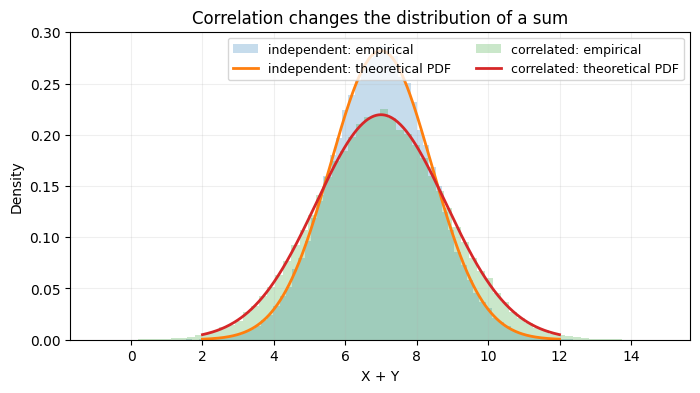

In [2]:
# Demonstration 1: the theory and the simulated sampling distribution agree.
mu, sigma, rho, B = 3.5, 1.0, 0.65, 120_000
x = rng.normal(mu, sigma, B)
eps = rng.normal(0, 1, B)
y_ind = rng.normal(mu, sigma, B)
y_corr = mu + rho*(x-mu) + np.sqrt(1-rho**2)*sigma*eps
z_ind, z_corr = x+y_ind, x+y_corr

zgrid = np.linspace(2, 12, 500)
fig, ax = plt.subplots()
for data, tag, var in [(z_ind, "independent", 2*sigma**2),
                       (z_corr, "correlated", 2*sigma**2*(1+rho))]:
    ax.hist(data, bins=70, density=True, alpha=.25, label=f"{tag}: empirical")
    ax.plot(zgrid, stats.norm.pdf(zgrid, 2*mu, np.sqrt(var)), lw=2,
            label=f"{tag}: theoretical PDF")
    print(f"{tag:12s} mean={np.mean(data):.3f}, variance={np.var(data):.3f}; ",
          f"theory variance={var:.3f}")
ax.set(xlabel="X + Y", ylabel="Density", title="Correlation changes the distribution of a sum")
ax.legend(ncol=2, fontsize=9)
plt.show()

## From individual observations to an estimator

For independent, identically distributed observations with finite variance $\sigma^2$,

$$\overline X=\frac{1}{n}\sum_{i=1}^n X_i,\qquad
\mathbb E[\overline X]=\mu,\qquad
\operatorname{Var}(\overline X)=\frac{\sigma^2}{n}.$$

The **standard deviation of the estimator across repeated samples** is the *standard error*:

$$\mathrm{SE}(\overline X)=\frac{\sigma}{\sqrt n}.$$

The standard deviation of the raw $X_i$ and the standard error of $\overline X$ answer different questions. A galaxy-to-galaxy scatter of $0.12$ mag does **not** imply a $0.12$ mag uncertainty on the mean from $n$ independent galaxies.

For independent Gaussian data, the sample median is less statistically efficient than the mean (asymptotically $\mathrm{SE}(\widetilde X)\simeq \sqrt{\pi/2}\,\sigma/\sqrt n$), but is less sensitive to extreme observations.

**Astronomy translation:** a median Hubble residual $\widetilde r$ is an estimator. Without its sampling uncertainty, comparing medians of two SN samples is not an inferential result.

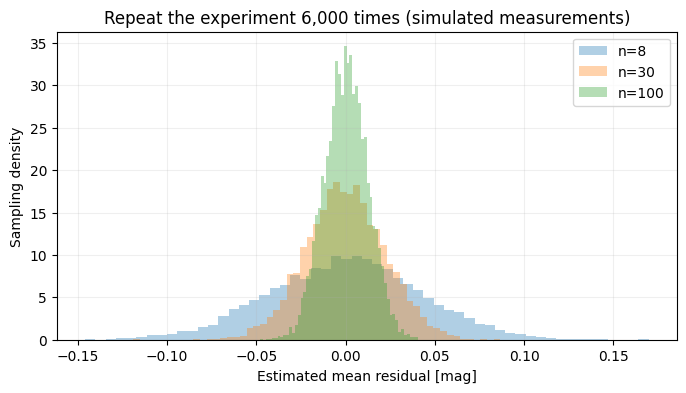

,Number of independent objects,MC SD of mean,sigma / sqrt(n)
0,8,0.042352,0.042426
1,30,0.022187,0.021909
2,100,0.012120,0.012000


In [3]:
# Demonstration 2: the sampling distribution narrows with n.
mu_true, intrinsic_sd, B = 0.0, .12, 6000
n_list = [8, 30, 100]
fig, ax = plt.subplots()
rows = []
for n in n_list:
    samples = rng.normal(mu_true, intrinsic_sd, (B, n))
    est = samples.mean(axis=1)
    rows.append([n, est.std(ddof=1), intrinsic_sd/np.sqrt(n)])
    ax.hist(est, bins=55, density=True, alpha=.35, label=f"n={n}")
ax.set(xlabel="Estimated mean residual [mag]", ylabel="Sampling density",
       title="Repeat the experiment 6,000 times (simulated measurements)")
ax.legend(); plt.show()
display(pd.DataFrame(rows, columns=["Number of independent objects", "MC SD of mean", "sigma / sqrt(n)"]))

### Think–pair–share (2 minutes)

Two groups yield medians $0.01$ and $0.03$ mag. Can we say they differ?

**Instructor answer:** $0.02$ mag is an *observed difference* (effect size). We cannot decide whether it is distinguishable from sampling variability without a sampling model, an uncertainty estimate, and knowledge of dependence/selection. A smaller *p*-value would not by itself imply an important cosmological shift.

---
# Part 2 (25–55 min) — Hypotheses, *p*-values, significance and power

A statistical test requires **more than choosing a test function**:

1. Specify the **scientific claim** and the associated null $H_0$ and alternative $H_1$.
2. State the **sampling mechanism** and assumptions under $H_0$.
3. Predefine an appropriate statistic $T(D)$ and an alternative-sensitive rejection region.
4. Evaluate how extreme $T_{\rm obs}$ is under the **null distribution**.
5. Report an *effect size* with uncertainty and explain what is—or is not—learned.

For a two-sided statistic whose large values signal incompatibility,

$$p=P_{H_0}\!\left(T(D)\ge T_{\rm obs}\right).$$

This is a probability of **data/test statistics, conditional on a specified model**. It is **not** $P(H_0\mid D)$, nor the probability that the result was caused by chance, nor a measurement of effect size.

For a standard normal test statistic $Z$,

$$p_{\rm two-sided}=2\,[1-\Phi(|Z_{\rm obs}|)].$$

Fix a significance level $\alpha$ *before* inspecting the result (e.g., $0.05$). The **type I error** of a valid level-$\alpha$ test is the probability of rejecting $H_0$ when it holds. Non-rejection is **not acceptance of $H_0$**.

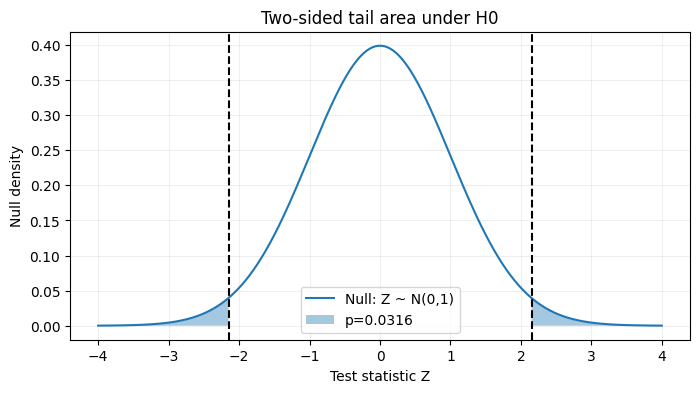

For |z|=2.15: p=0.03156, alpha=0.05. Decision: reject H0.


In [4]:
# Demonstration 3: calculate a two-sided p-value as a tail area.
z_obs, alpha = 2.15, 0.05
p_two = 2 * stats.norm.sf(abs(z_obs))
xx = np.linspace(-4.0, 4.0, 1000)
yy = stats.norm.pdf(xx)
fig, ax = plt.subplots()
ax.plot(xx, yy, label="Null: Z ~ N(0,1)")
ax.fill_between(xx, 0, yy, where=np.abs(xx) >= abs(z_obs), alpha=.4, label=f"p={p_two:.4f}")
for xc in (-z_obs, z_obs): ax.axvline(xc, ls="--", color="black")
ax.set(xlabel="Test statistic Z", ylabel="Null density", title="Two-sided tail area under H0")
ax.legend(); plt.show()
print(f"For |z|={z_obs:.2f}: p={p_two:.5f}, alpha={alpha}. "
      f"Decision: {'reject' if p_two < alpha else 'do not reject'} H0.")

## Confidence intervals, effect size and scientific significance

Consider a mean residual $\mu_r$ measured from $n$ independent Gaussian observations. For known variance, a symmetric $100(1-\alpha)\%$ interval is

$$\overline r\ \pm\ z_{1-\alpha/2}\frac{\sigma}{\sqrt n}.$$

For unknown variance under the classical Gaussian independent-sample assumptions, replace $\sigma$ with $s$ and $z$ with a Student's $t_{n-1}$ quantile.

A $95\%$ confidence interval does **not** say there is a $95\%$ posterior probability that the fixed parameter lies in this particular interval. It describes the **long-run coverage** of the interval-producing procedure under its assumptions.

An effect size such as $\Delta_{\rm med}=\mathrm{med}(r_{\rm high})-\mathrm{med}(r_{\rm low})$ has physical units of mag. An *astronomically meaningful* threshold should be discussed separately from a *p*-value.

### Errors and power
- **Type I error:** reject a true $H_0$; controlled at $\alpha$ when the test is valid.
- **Type II error ($\beta$):** fail to reject $H_0$ when a particular $H_1$ is true.
- **Power:** $1-\beta$, a function of the effect size, noise and sample size.

**Predict:** holding an astrophysical offset fixed, what happens to detection power if we quadruple the independent sample size? What if the fourfold dataset contains highly correlated repeated measurements instead?

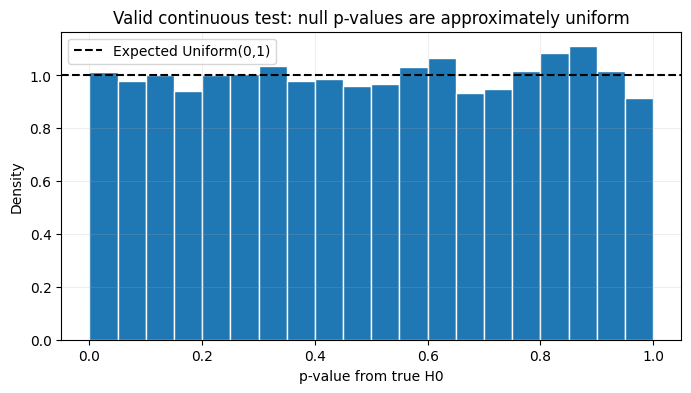

,True shift [mag],Independent sample n,Simulated rejection fraction
0,0.000,25,0.048833
1,0.025,25,0.175250
2,0.060,25,0.709417


In [5]:
# Demonstration 4: null p-values and power depend on the sampling model.
B, n, sigma, alpha = 12000, 25, .12, .05
z_null = rng.normal(size=B)  # null distribution of Z when variance is known
p_null = 2*stats.norm.sf(np.abs(z_null))
delta_grid = [0, .025, .06]
results=[]
for shift in delta_grid:
    estimates = rng.normal(loc=shift, scale=sigma/np.sqrt(n), size=B)
    z = estimates / (sigma/np.sqrt(n))
    reject = (2*stats.norm.sf(np.abs(z)) < alpha)
    results.append([shift, n, reject.mean()])
fig, ax=plt.subplots()
ax.hist(p_null, bins=np.linspace(0, 1, 21), density=True, edgecolor="white")
ax.axhline(1, ls="--", color="black", label="Expected Uniform(0,1)")
ax.set(xlabel="p-value from true H0", ylabel="Density",
       title="Valid continuous test: null p-values are approximately uniform")
ax.legend(); plt.show()
display(pd.DataFrame(results, columns=["True shift [mag]", "Independent sample n", "Simulated rejection fraction"]))

### Instructor pause: interpreting the simulation

1. Why is the rejection fraction near $\alpha$ for zero shift?  
2. Why does power increase with shift?  
3. Can a small *p*-value distinguish unmodelled calibration offsets from new physics?  

**Discussion notes:** (1) controlled type I error under a correctly specified null, (2) displacement of the sampling distribution relative to the null, and (3) **no**—the statistical contrast does not identify a physical cause. An incomplete model and an incorrect error budget can produce apparently decisive evidence.

---
# Part 3 (55–75 min) — Z tests, t tests and correlated astronomical measurements

For $X_i$ that are **independent normal** draws with mean $\mu$, known standard deviation $\sigma$:

$$Z=\frac{\overline X-\mu_0}{\sigma/\sqrt n}\sim\mathcal N(0,1)\quad\text{under }H_0:\mu=\mu_0.$$

If the population $\sigma$ is unknown and estimated from the same data,

$$T=\frac{\overline X-\mu_0}{s/\sqrt n}\sim t_{n-1},\qquad
s^2=\frac{1}{n-1}\sum_{i=1}^n(X_i-\overline X)^2.$$

The finite-sample exact $t$ result requires normally distributed independent observations. Other settings may admit approximations, but not by substituting a $t$ distribution automatically. **One-sided versus two-sided** testing must be fixed based on the scientific question, not after seeing the sign.

An observational subtlety: the sample standard deviation $s$ measures empirical scatter; it is not necessarily the physically complete measurement covariance. Intrinsic scatter, heteroscedastic reported errors, common calibration and selection require additional modelling.

In [6]:
# Demonstration 5: the same sample, distinct known-sigma and estimated-sigma tests.
n, mu0, known_sigma = 13, 0, .12
sample = rng.normal(.045, known_sigma, size=n)  # mock residuals, for teaching only
mean, s = sample.mean(), sample.std(ddof=1)
z = (mean-mu0) / (known_sigma/np.sqrt(n))
t = (mean-mu0) / (s/np.sqrt(n))
p_z = 2*stats.norm.sf(abs(z))
p_t = 2*stats.t.sf(abs(t), df=n-1)
ci_t = stats.t.interval(.95, df=n-1, loc=mean, scale=s/np.sqrt(n))
print(f"n={n}; observed mean={mean:.4f} mag; empirical s={s:.4f} mag")
print(f"Z-test (sigma assumed known) Z={z:.3f}, p={p_z:.4f}")
print(f"t-test (sigma estimated) t={t:.3f}, p={p_t:.4f}")
print(f"95% t-based mean interval: [{ci_t[0]:+.4f}, {ci_t[1]:+.4f}] mag")
print("Cross-check scipy.stats.ttest_1samp:", stats.ttest_1samp(sample, popmean=0))

n=13; observed mean=0.0398 mag; empirical s=0.1041 mag
Z-test (sigma assumed known) Z=1.196, p=0.2319
t-test (sigma estimated) t=1.378, p=0.1933
95% t-based mean interval: [-0.0231, +0.1027] mag
Cross-check scipy.stats.ttest_1samp: TtestResult(statistic=np.float64(1.37830056931471), pvalue=np.float64(0.19326593009138684), df=np.int64(12))


## Derive the uncertainty of a mean with correlated errors

Let $\mathbf X=(X_1,\dots,X_n)^{\mathsf T}$ have covariance matrix $C$, and $\mathbf 1$ denote a vector of ones. Since

$$\overline X=\frac{1}{n}\mathbf 1^{\mathsf T}\mathbf X,$$

it follows that

$$\boxed{\operatorname{Var}(\overline X)=\frac{1}{n^2}\mathbf 1^{\mathsf T}C\mathbf 1
=\frac{1}{n^2}\sum_{i,j}\operatorname{Cov}(X_i,X_j).}$$

If each observation has variance $\sigma^2$ and every distinct pair has correlation $\rho$ (equicorrelated toy model),

$$\operatorname{Var}(\overline X)=\frac{\sigma^2}{n}\left[1+(n-1)\rho\right],\qquad
n_{\rm eff}=\frac{n}{1+(n-1)\rho}.$$

For $\rho>0$, **adding rows does not recover $1/\sqrt n$ precision indefinitely**. The equicorrelation model is an illustration, *not* the Pantheon+ covariance.

**Why this is central to cosmology:** if many standardized candles share a zero-point or calibration systematic, that common contribution survives averaging. In Week 3 students will learn to represent it with a full covariance likelihood.

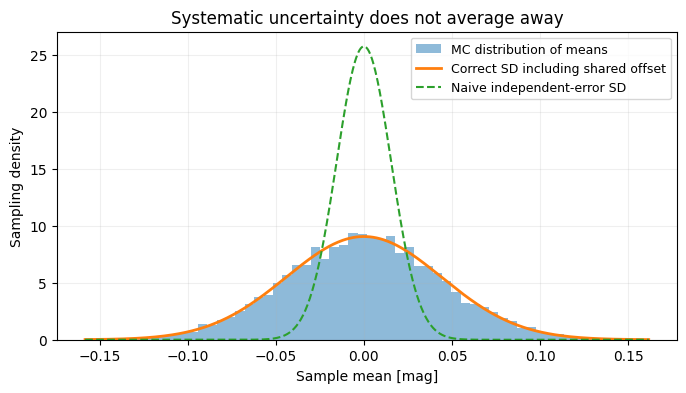

n=60, rho=0.12; nominal n=60, effective n≈7.43
naive SE=0.0155 mag; theory correlated SE=0.0440 mag; simulated SE=0.0443 mag


In [7]:
# Demonstration 6: shared systematic floor versus naive sigma/sqrt(n).
B, n, rho, sigma = 9000, 60, .12, .12
common = rng.normal(0, sigma*np.sqrt(rho), size=(B,1))
noise  = rng.normal(0, sigma*np.sqrt(1-rho), size=(B,n))
means = (common+noise).mean(axis=1)
se_naive = sigma/np.sqrt(n)
se_true = sigma*np.sqrt((1+(n-1)*rho)/n)
fig, ax = plt.subplots()
ax.hist(means, bins=60, density=True, alpha=.5, label="MC distribution of means")
x = np.linspace(means.min(), means.max(), 500)
ax.plot(x, stats.norm.pdf(x,0,se_true), lw=2, label="Correct SD including shared offset")
ax.plot(x, stats.norm.pdf(x,0,se_naive), ls="--", label="Naive independent-error SD")
ax.set(xlabel="Sample mean [mag]", ylabel="Sampling density", title="Systematic uncertainty does not average away")
ax.legend(fontsize=9); plt.show()
print(f"n={n}, rho={rho}; nominal n={n}, effective n≈{n/(1+(n-1)*rho):.2f}")
print(f"naive SE={se_naive:.4f} mag; theory correlated SE={se_true:.4f} mag; simulated SE={means.std(ddof=1):.4f} mag")

### Key question before the break

A public astronomical catalogue contains several entries for the same physical supernova, and some light curves share instrument calibration. Does its number of **rows** equal the number of independent statistical units?

**Instructor answer:** generally not. Repeated entries may need an object-level treatment; shared calibration needs a covariance or hierarchical model. Resampling arbitrary rows can give overconfident intervals. A *single* universal effective sample size rarely captures all the dependence in a real covariance matrix.

---
# Part 4 (75–90 min) — Central limit theorem: scope and counterexamples

For independent identically distributed $X_i$ with finite mean $\mu$ and finite, non-zero variance $\sigma^2$, the classical CLT states

$$\frac{\sqrt n(\overline X-\mu)}{\sigma}\xrightarrow{d}\mathcal N(0,1).$$

**What becomes approximately Gaussian is the distribution of the scaled sample mean**, not the original observations. The CLT does not guarantee correctness for small $n$, arbitrary dependencies, infinite-variance distributions, medians or systematically selected samples. More general CLTs exist, but need explicit conditions.

**Cosmology interpretation:** intrinsically skewed residual-like data may still yield a reasonably Gaussian *sampling mean* for sufficiently large independent samples, but fitting a Gaussian likelihood to raw individual residuals is an **additional modelling decision**.

**Predict:** does an exponential distribution of individual values become symmetric when $n$ increases? What *does* become symmetric?

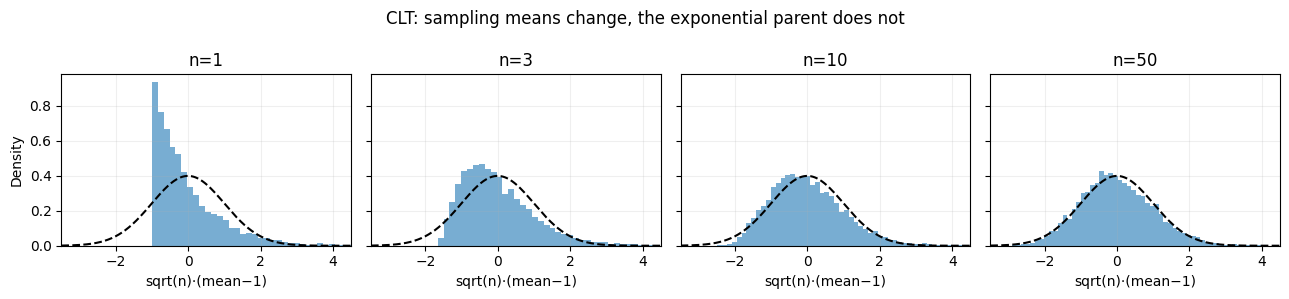

In [8]:
# Demonstration 7: asymmetric individual draws; increasingly normal mean.
B, n_values = 7000, [1, 3, 10, 50]
fig, axes = plt.subplots(1, len(n_values), figsize=(13, 3), sharey=True)
xx=np.linspace(-3.5, 4.5, 550)
for n, ax in zip(n_values,axes):
    raw = rng.exponential(scale=1.0, size=(B,n))
    standardized_mean = (raw.mean(axis=1)-1.0)*np.sqrt(n)
    ax.hist(standardized_mean, bins=55, density=True, alpha=.6)
    ax.plot(xx, stats.norm.pdf(xx), 'k--', lw=1.5)
    ax.set(title=f"n={n}", xlim=(-3.5,4.5), xlabel="sqrt(n)·(mean−1)")
axes[0].set_ylabel("Density")
fig.suptitle("CLT: sampling means change, the exponential parent does not")
plt.tight_layout(); plt.show()

### Optional advanced note: infinite variance

For a Cauchy-distributed variable, a population mean and variance do not exist. Its sample mean does **not** concentrate as $n$ grows in the manner predicted by the finite-variance CLT; the average of independent standard Cauchy observations is again Cauchy-distributed. In observational work, very heavy tails motivate robust summaries, realistic outlier models and careful uncertainty diagnostics—not just larger sample sizes.

## **Break (90–100 min)**

---
# Part 5 (100–120 min) — Distribution tests, ECDFs and what is being tested

The **empirical cumulative distribution function** of observations $x_1,\ldots,x_n$ is

$$F_n(t)=\frac{1}{n}\sum_{i=1}^n \mathbb I(x_i\le t).$$

Unlike a histogram, an ECDF does not depend on arbitrary bin edges. The one-sample Kolmogorov–Smirnov statistic with a **fully specified** continuous null CDF $F_0$ is

$$D_n=\sup_t |F_n(t)-F_0(t)|.$$

For **two independent samples**, $D_{n,m}=\sup_t|F_n(t)-G_m(t)|$. These tests ask about the overall distributions, not only the difference in means.

### Important qualification
The usual one-sample KS *p*-value is **not calibrated** if the model mean and variance were estimated from that same sample and then treated as fixed. This is related to the Lilliefors problem. Use an appropriate adjusted procedure such as a parametric bootstrap under the fitted null, or a supported test with the appropriate calibration.

A Shapiro–Wilk test addresses Gaussianity of the sampled distribution. In cosmological inference, the relevant distribution may be **whitened residuals under the likelihood model**, not raw magnitudes or all residuals lumped across surveys.

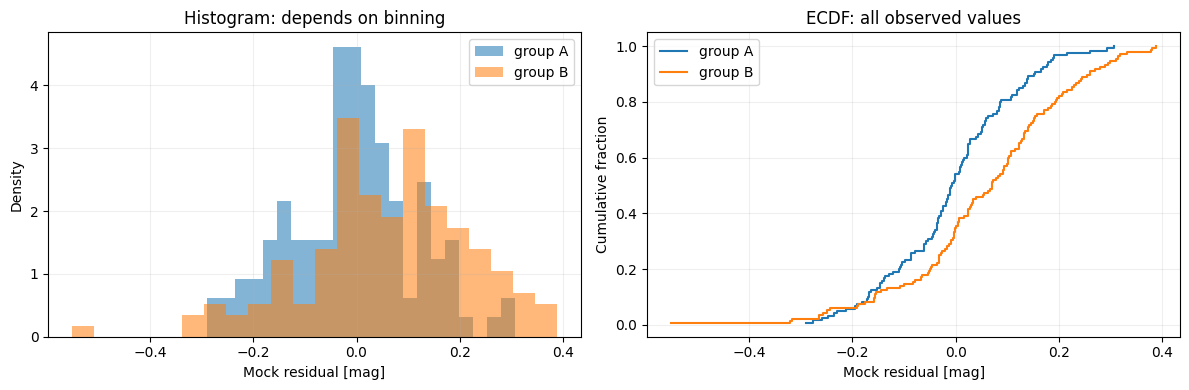

Two-sample KS: D=0.269, p=0.0002
Difference in means = +0.0645 mag; difference in SD = +0.0385 mag


In [9]:
# Demonstration 8: compare empirical CDFs and what a two-sample KS test detects.
a = rng.normal(0.00, 0.12, 120)
b = rng.normal(0.04, 0.16, 135)   # deliberate difference in location AND scale
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].hist(a,bins=22,alpha=.55,label="group A",density=True)
axes[0].hist(b,bins=22,alpha=.55,label="group B",density=True)
for xx,lab in [(a,"group A"),(b,"group B")]:
    sorted_x=np.sort(xx)
    ecdf=np.arange(1,len(xx)+1)/len(xx)
    axes[1].step(sorted_x,ecdf,where="post",label=lab)
axes[0].set(xlabel="Mock residual [mag]",ylabel="Density",title="Histogram: depends on binning")
axes[1].set(xlabel="Mock residual [mag]",ylabel="Cumulative fraction",title="ECDF: all observed values")
for ax in axes: ax.legend()
plt.tight_layout();plt.show()
res=stats.ks_2samp(a,b)
print(f"Two-sample KS: D={res.statistic:.3f}, p={res.pvalue:.4f}")
print(f"Difference in means = {np.mean(b)-np.mean(a):+.4f} mag; difference in SD = {np.std(b,ddof=1)-np.std(a,ddof=1):+.4f} mag")

## What if we fit the null distribution before testing it?

Imagine a sample of $n$ residuals whose distribution may be Gaussian with **unknown** mean and variance. A naive procedure would compute

$$D_{\rm obs}=\sup_x\left|F_n(x)-\Phi\!\left(\frac{x-\widehat\mu}{\widehat\sigma}\right)\right|$$

and use the standard KS null distribution. However, the fit was optimized using the same observations. The standard KS calibration assumes a fixed, specified $F_0$.

### One suitable learning strategy: parametric refit-bootstrap
1. Fit $(\widehat\mu,\widehat\sigma)$ on the observed sample; evaluate $D_{\rm obs}$.
2. Simulate an independent sample from $\mathcal N(\widehat\mu,\widehat\sigma^2)$.
3. **Refit** its mean and standard deviation using the same method as for the original sample.
4. Recompute its statistic; repeat to obtain the null distribution.
5. Compare $D_{\rm obs}$ to the refitted null statistics.

This illustration relies on the Gaussian family being correctly specified under the composite null, and the parametric bootstrap provides a **simulation-based approximation**, not an exact universal KS calibration.

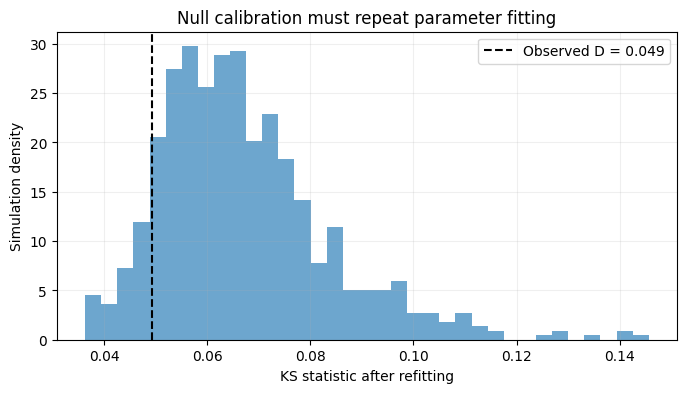

Naive one-sample KS p (INVALID fitted-null calibration): 0.9797
Refitted parametric-bootstrap approximate p: 0.9073


In [10]:
# Demonstration 9: contrast ordinary KS p-value with refitted parametric-bootstrap calibration.
x = rng.normal(loc=.02, scale=.13, size=85)  # a pedagogical simulated sample

def fitted_ks_stat(sample):
    loc = np.mean(sample)
    scale = np.std(sample, ddof=0)  # Gaussian ML scale estimate (not sample SD)
    return stats.kstest(sample, stats.norm(loc,scale).cdf).statistic, loc, scale

D_obs, loc_hat, scale_hat = fitted_ks_stat(x)
naive_p = stats.kstest(x, stats.norm(loc_hat,scale_hat).cdf).pvalue
B = 700
Ds = np.empty(B)
for j in range(B):
    null_sample = rng.normal(loc_hat, scale_hat, size=len(x))
    Ds[j], _, _ = fitted_ks_stat(null_sample)
p_adjusted = (np.sum(Ds >= D_obs) + 1) / (B + 1)
fig,ax=plt.subplots()
ax.hist(Ds,bins=35,density=True,alpha=.65)
ax.axvline(D_obs,ls='--',color='black',label=f'Observed D = {D_obs:.3f}')
ax.set(xlabel='KS statistic after refitting',ylabel='Simulation density',title='Null calibration must repeat parameter fitting')
ax.legend();plt.show()
print(f"Naive one-sample KS p (INVALID fitted-null calibration): {naive_p:.4f}")
print(f"Refitted parametric-bootstrap approximate p: {p_adjusted:.4f}")

### Instructor prompt (2 minutes)

Why might a normality test give a very small *p*-value in a dataset with thousands of measurements even when the departures from a Gaussian model are scientifically negligible? Why might a non-significant KS result be poor evidence that a cosmological model is correct?

**Discussion notes:** test sensitivity increases with information/sample size; model adequacy is about consequences for parameters and predictions, not merely failing to reject one hypothesis. Different diagnostics test different components of a generative model. Residual patterns versus redshift, survey and reported uncertainty may be more revealing than an omnibus normality test.

---
# Part 6 (120–145 min) — Permutation testing and exchangeability

For two samples $A$ and $B$, take a **pre-specified** statistic such as

$$T_{\rm obs}=|\operatorname{median}(B)-\operatorname{median}(A)|.$$

Under a null in which the observed values are **exchangeable under relabelling**, repeatedly permute labels while preserving original group sizes. If $T^{(b)}$ is the statistic after permutation $b$,

$$\widehat p=\frac{1+\sum_{b=1}^{B}\mathbb I(T^{(b)}\ge T_{\rm obs})}{B+1}.$$

The $+1$ includes the observed ordering when using sampled permutations and prevents a Monte Carlo estimate of zero. A permutation test can be exactly calibrated under suitable exchangeability, but is **not assumption free**.

**What is exchangeability?** Under $H_0$, the joint distribution of the observations is unchanged by the permutations used in the test. If group membership is coupled to selection, survey calibration, heteroscedastic errors or correlated observations, arbitrarily reassigning rows may not simulate the intended scientific null.

**Important nuance:** a permutation test for equality of full distributions has different assumptions from tests designed for equality of means under unequal group variances. The correct randomization scheme and statistic depend on the precise null question.

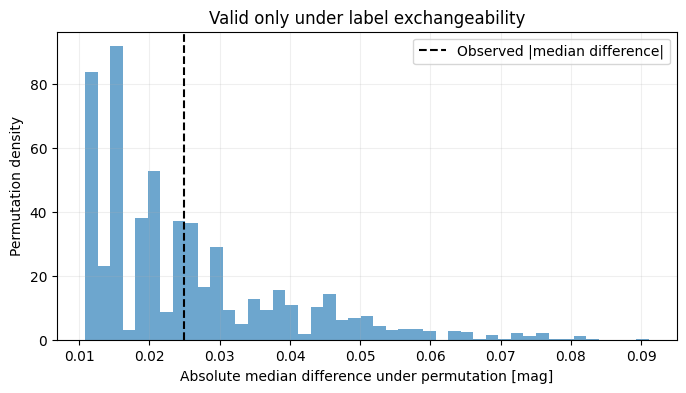

Observed signed median B−A = +0.0249 mag; two-sided permutation p≈0.4310


In [11]:
# Demonstration 10: a median difference, its permutation null, and an effect size.
a = rng.normal(0, .12, 45)
b = rng.normal(.045, .12, 45)

def permutation_difference(a, b, B=3999, random_state=None):
    prng = np.random.default_rng(123) if random_state is None else random_state
    a = np.asarray(a); b = np.asarray(b)
    observed_signed = float(np.median(b) - np.median(a))
    pooled = np.concatenate([a,b]); n_a = len(a)
    null = np.empty(B)
    for k in range(B):
        p = prng.permutation(pooled)
        null[k] = abs(np.median(p[n_a:])-np.median(p[:n_a]))
    p_value=(1+np.count_nonzero(null >= abs(observed_signed)))/(B+1)
    return observed_signed, null, p_value

delta, null, p_perm=permutation_difference(a,b,B=3999,random_state=rng)
fig,ax=plt.subplots()
ax.hist(null,bins=45,density=True,alpha=.65)
ax.axvline(abs(delta),ls='--',color='black',label='Observed |median difference|')
ax.set(xlabel='Absolute median difference under permutation [mag]',
       ylabel='Permutation density',title='Valid only under label exchangeability')
ax.legend();plt.show()
print(f"Observed signed median B−A = {delta:+.4f} mag; two-sided permutation p≈{p_perm:.4f}")

## The observational pitfall: a spurious redshift effect from survey composition

Astronomers often compare low-$z$ and high-$z$ objects. But suppose *low redshift contains mostly survey A* and *high redshift contains mostly survey B*, with different residual calibration zero-points. Then a pooled group difference can be driven by **survey composition**, even if the true physical redshift effect is zero **within each survey**.

This is a **confounding / selection** demonstration, not an assertion about any real SN compilation. Row permutation can answer a mathematical exchangeability null while failing to isolate the causal/physical effect you intended to test.

**Predict before running:** Will the pooled high−low difference be close to zero, or could it resemble an astrophysical evolution effect?

Counts by survey and redshift group:


redshift_group,high,low
survey,,
A,40,160
B,160,40


Mean residuals within each survey [mag]:


redshift_group,high,low
survey,,
A,0.063603,0.050620
B,-0.046962,-0.075299


Pooled high−low mean = -0.0503 mag
Within A high−low = +0.0130 mag
Within B high−low = +0.0283 mag


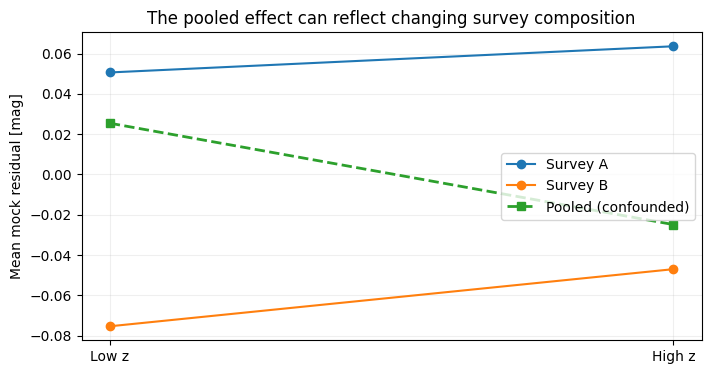

In [12]:
# Demonstration 11: mock survey confounding; zero true redshift evolution within each survey.
# Survey A mostly low z, Survey B mostly high z.
mock = pd.DataFrame({
    'survey': np.repeat(['A','A','B','B'], [160,40,40,160]),
    'redshift_group': np.repeat(['low','high','low','high'], [160,40,40,160])
})
mock['survey_offset'] = np.where(mock['survey']=='A', .06, -.06)
mock['residual'] = mock['survey_offset'] + rng.normal(0,.11,len(mock))
pooled = mock.groupby('redshift_group')['residual'].mean()
within = mock.groupby(['survey','redshift_group'])['residual'].mean().unstack()
print('Counts by survey and redshift group:')
display(pd.crosstab(mock.survey,mock.redshift_group))
print('Mean residuals within each survey [mag]:')
display(within)
print(f"Pooled high−low mean = {pooled['high']-pooled['low']:+.4f} mag")
print(f"Within A high−low = {within.loc['A','high']-within.loc['A','low']:+.4f} mag")
print(f"Within B high−low = {within.loc['B','high']-within.loc['B','low']:+.4f} mag")
fig,ax=plt.subplots()
for survey in ['A','B']:
    sub=mock[mock.survey==survey]
    grp=sub.groupby('redshift_group')['residual'].mean()
    ax.plot([0,1],[grp['low'],grp['high']],marker='o',label=f'Survey {survey}')
ax.plot([0,1],[pooled['low'],pooled['high']],marker='s',lw=2,ls='--',label='Pooled (confounded)')
ax.set(xticks=[0,1],xticklabels=['Low z','High z'],ylabel='Mean mock residual [mag]',
       title='The pooled effect can reflect changing survey composition')
ax.legend();plt.show()

### Discussion: which hypothesis did we actually test?

- **Null A:** All observations have the same distribution, so arbitrary redshift labels are exchangeable.
- **Null B:** There is no intrinsic redshift dependence **at fixed survey and calibration**.

These are **not the same scientific null**. The survey-composition simulation violates Null A, yet may be compatible with Null B. A naive permutation comparison can detect mixture differences without establishing cosmological evolution.

For real data, consider survey-stratified analyses, explicitly modelled systematics, hierarchical likelihoods, or scientifically justified restricted permutations. Simply switching to a “non-parametric” test does not remove the design problem.

---
# Part 7 (145–165 min) — Bootstrap and the unit of resampling

The **non-parametric bootstrap** approximates sampling uncertainty by repeatedly drawing $n$ values **with replacement** from the observed sample and recalculating an estimator:

$$D^{*(b)}\sim\widehat F_n,\qquad \widehat\theta^{*(b)}=T(D^{*(b)}).$$

For a scalar estimator, a simple *percentile interval* is

$$\left[Q_{0.025}(\widehat\theta^*),\ Q_{0.975}(\widehat\theta^*)\right].$$

This is **not always an accurate 95% interval**: bias, skewness, sample size and dependence affect its coverage. More refined intervals (e.g., BCa), model-based uncertainty or covariance-aware resampling may be needed.

### Do not confuse these procedures

| Procedure | What is re-created? | Typical goal | Primary assumption |
|---|---|---|---|
| Non-parametric bootstrap | Observed sampling units with replacement | Sampling variability / CI | Units representative and suitably independent for *ordinary* bootstrap |
| Permutation | Labels or assignments under $H_0$ | Null-test tail probability | Exchangeability (possibly restricted to strata/blocks) |
| Parametric bootstrap | New outcomes from a fitted stochastic model | Model-based sampling distribution | Correct parametric data-generation model |

For astronomical datasets with repeated epochs or repeated entries, ordinary **row** resampling may be invalid: the unit of resampling is often the *physical source*, observed night, field or correlated block.

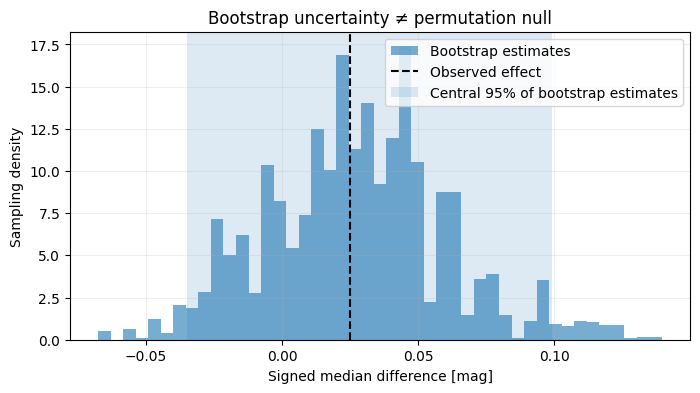

Observed effect: +0.0249 mag, basic percentile interval [-0.0349, +0.0993] mag
Separate question from permutation p=0.4310 under exchangeability.


In [13]:
# Demonstration 12: ordinary bootstrap confidence interval for a difference in medians.
def bootstrap_median_difference(a, b, B=3500, random_state=None):
    brng = np.random.default_rng(1234) if random_state is None else random_state
    a=np.asarray(a); b=np.asarray(b)
    boot=np.empty(B)
    for j in range(B):
        boot[j]=np.median(brng.choice(b,len(b),replace=True))-np.median(brng.choice(a,len(a),replace=True))
    return boot

# Reuse the independently generated groups A and B from Demonstration 10.
boot=bootstrap_median_difference(a,b,B=3500,random_state=rng)
low, high = np.quantile(boot,[.025,.975])
fig,ax=plt.subplots()
ax.hist(boot,bins=45,density=True,alpha=.6,label='Bootstrap estimates')
ax.axvline(delta,ls='--',color='black',label='Observed effect')
ax.axvspan(low,high,alpha=.15,label='Central 95% of bootstrap estimates')
ax.set(xlabel='Signed median difference [mag]',ylabel='Sampling density',title='Bootstrap uncertainty ≠ permutation null')
ax.legend();plt.show()
print(f"Observed effect: {delta:+.4f} mag, basic percentile interval [{low:+.4f}, {high:+.4f}] mag")
print(f"Separate question from permutation p={p_perm:.4f} under exchangeability.")

## Row bootstrap versus source-level (cluster) bootstrap

Suppose we have $N_\mathrm{SN}$ physical objects, each measured $k$ times. Let

$$r_{ij}=u_i+e_{ij},\qquad u_i\sim\mathcal N(0,\tau^2),\quad e_{ij}\sim\mathcal N(0,\sigma_e^2).$$

Measurements within a source share the latent $u_i$ and therefore are correlated. Naive resampling of all $Nk$ measurements treats them as independent and may underestimate uncertainty.

A **cluster bootstrap** instead resamples whole physical objects (all their observations together), preserving within-object dependence. The next example makes the distinction visible. This toy demonstrates one random-effects structure; it is **not** a surrogate for Pantheon+ statistical/systematic covariance.

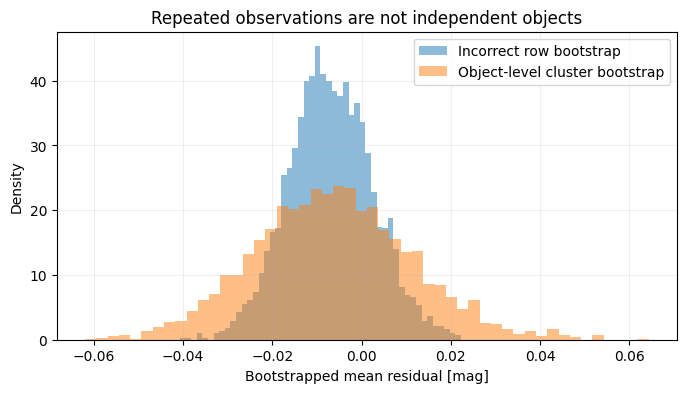

Row resampling      SD=0.0095; 95% percentile interval = [-0.0255,+0.0121]
Cluster resampling  SD=0.0176; 95% percentile interval = [-0.0400,+0.0293]


In [14]:
# Demonstration 13: repeated mock observations; compare row and cluster bootstraps.
N_OBJECTS, K_REPEAT, B_BOOT = 42, 4, 3000
latent = rng.normal(0, .11, size=N_OBJECTS)
measurements = latent[:,None] + rng.normal(0,.045,size=(N_OBJECTS,K_REPEAT))
flat = measurements.ravel()
row_est = np.empty(B_BOOT)
cluster_est = np.empty(B_BOOT)
for j in range(B_BOOT):
    row_est[j] = rng.choice(flat,size=flat.size,replace=True).mean()
    indices = rng.integers(N_OBJECTS,size=N_OBJECTS)
    cluster_est[j] = measurements[indices,:].mean()
fig,ax=plt.subplots()
ax.hist(row_est,bins=50,density=True,alpha=.5,label='Incorrect row bootstrap')
ax.hist(cluster_est,bins=50,density=True,alpha=.5,label='Object-level cluster bootstrap')
ax.set(xlabel='Bootstrapped mean residual [mag]',ylabel='Density',
       title='Repeated observations are not independent objects')
ax.legend();plt.show()
for name, estimates in [('Row resampling',row_est),('Cluster resampling',cluster_est)]:
    lo,hi=np.quantile(estimates,[.025,.975])
    print(f"{name:19s} SD={estimates.std(ddof=1):.4f}; 95% percentile interval = [{lo:+.4f},{hi:+.4f}]")

### Instructor discussion: What about the covariance?

In Lab 02, students may group multiple entries sharing an object ID (`CID`) **for descriptive resampling**. Doing so makes object-level resampling more sensible than drawing duplicate rows independently, but collapsing measurements by a median does **not** reproduce the released joint likelihood, and does not eliminate covariance across different SNe.

**Preview of Week 3:** with observed vector $\mathbf m$ and covariance $C$,

$$-2\ln\mathcal L(\theta)=\big(\mathbf m-\mathbf m_{\rm model}(\theta)\big)^\mathsf TC^{-1}
\big(\mathbf m-\mathbf m_{\rm model}(\theta)\big)+\ln\det C+n\ln(2\pi)$$

for a multivariate Gaussian data model. **Only when $C$ is parameter-independent** may the final two terms be dropped for parameter maximization. The $C$-based likelihood is not interchangeable with an i.i.d. bootstrap.

---
# Part 8 (165–175 min) — Multiple testing and the look-elsewhere effect

Consider a planned comparison at one redshift threshold, versus a researcher who tests 15 thresholds and then reports only the smallest *p*-value. The latter procedure has searched over **many possible claims**. Even if there is **no** true redshift effect, the largest-looking discrepancy becomes more extreme when enough choices are tried.

If $K$ independent tests each have type I error $\alpha$, the chance of at least one false rejection is

$$P(\text{one or more false positives})=1-(1-\alpha)^K.$$

In practice, tests at nearby redshift cuts are **strongly correlated**, so this formula is illustrative, not directly applicable to the scan. A principled approach is to pre-register one primary split, report others as sensitivity analyses, or **calibrate the entire maximum-over-cuts statistic** under a null model.

**Astronomy extension:** this is the same reasoning behind a look-elsewhere effect in a wide frequency search for periodic AGN light curves. Testing many periods and sources requires a null calibration of the actual search protocol, not a single preselected-period *p*-value.

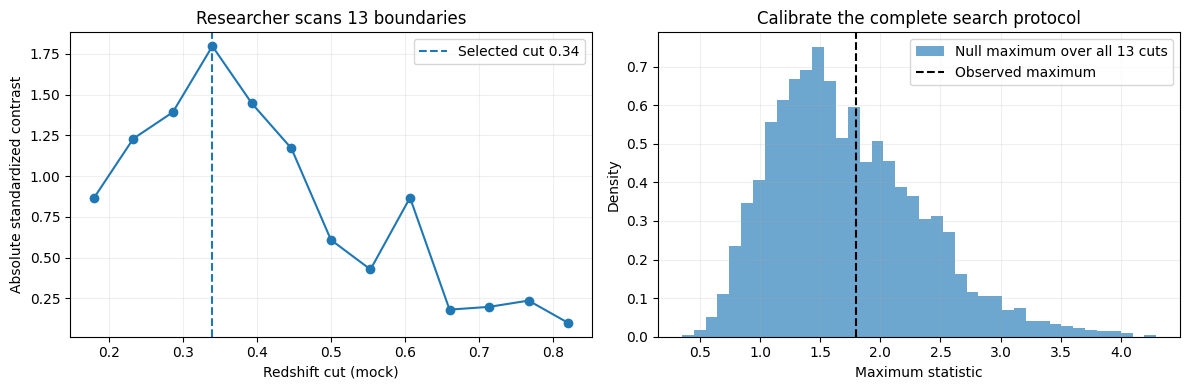

Selected cut: z=0.340; selected-cut nominal permutation p≈0.1013
Corrected max-scan permutation p≈0.4021


In [15]:
# Demonstration 14: comparing a selected split to a permutation-calibrated max-scan.
N, B_PERM = 260, 2200
z_mock = rng.uniform(0.03,1.0,N)  # strictly illustrative redshift labels
residual_mock = rng.normal(0,.12,N)  # NULL: no true redshift effect
cuts = np.linspace(.18,.82,13)
masks = np.array([z_mock < c for c in cuts])
nlow=masks.sum(axis=1); nhigh=N-nlow
assert (nlow > 20).all() and (nhigh > 20).all()

def scan_statistics(residuals):
    # fixed-design, equal-variance standardized group difference (not fitted p-values)
    low_sum=masks @ residuals
    total=np.sum(residuals)
    low_avg=low_sum/nlow
    high_avg=(total-low_sum)/nhigh
    return np.abs(high_avg-low_avg)/(.12*np.sqrt(1/nlow+1/nhigh))

observed_scan=scan_statistics(residual_mock)
kbest=np.argmax(observed_scan)
max_null=np.empty(B_PERM)
selected_null=np.empty(B_PERM)
for j in range(B_PERM):
    values=rng.permutation(residual_mock)
    scan=scan_statistics(values)
    max_null[j]=scan.max()
    selected_null[j]=scan[kbest]

selected_p=(1+(selected_null>=observed_scan[kbest]).sum())/(B_PERM+1)
global_p=(1+(max_null>=observed_scan[kbest]).sum())/(B_PERM+1)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(cuts,observed_scan,'o-')
axes[0].axvline(cuts[kbest],ls='--',label=f'Selected cut {cuts[kbest]:.2f}')
axes[0].set(xlabel='Redshift cut (mock)',ylabel='Absolute standardized contrast',
            title='Researcher scans 13 boundaries')
axes[0].legend()
axes[1].hist(max_null,bins=40,density=True,alpha=.65,label='Null maximum over all 13 cuts')
axes[1].axvline(observed_scan[kbest],ls='--',color='black',label='Observed maximum')
axes[1].set(xlabel='Maximum statistic',ylabel='Density',title='Calibrate the complete search protocol')
axes[1].legend()
plt.tight_layout();plt.show()
print(f"Selected cut: z={cuts[kbest]:.3f}; selected-cut nominal permutation p≈{selected_p:.4f}")
print(f"Corrected max-scan permutation p≈{global_p:.4f}")
assert global_p + 1e-12 >= selected_p  # same permutations, larger max statistic

### Essential caveat for the multiple-testing demonstration

The global permutation above is justified only for the **constructed iid null simulation**. If real residuals have redshift-dependent variance, survey structure or cross-source correlations, permuting all residuals destroys their data-generating structure. For real cosmological data we must instead build a null distribution that respects survey, calibration and dependence. The correction for multiple comparisons must be built on a **valid single-test/null model**.

---
# Part 9 (175–180 min) — From lecture reasoning to real Pantheon+ Lab 02

The graded laboratory uses **observational** Pantheon+ data. Its scientific question is deliberately different from the simulated demonstrations in this lecture:

> What descriptive structure is present in a real Hubble diagram, and how robustly can we quantify it without claiming to have completed a cosmological parameter fit?

**Workflow for the laboratory:**
1. Audit the published file and its columns, calibrators, repeated source IDs, redshifts and missing entries.
2. Choose and explicitly state a **reference cosmology** for descriptive residuals (not an estimated cosmology).
3. Define an effect: $\Delta_{\mathrm{med}}=\operatorname{med}(r_{\rm high-z})-\operatorname{med}(r_{\rm low-z})$.
4. Use bootstrap to estimate uncertainty at an appropriate observational unit; explain remaining covariance limitations.
5. Use a permutation test only after discussing whether **exchangeability** is a defensible approximation.
6. Compare ECDFs, redshift-boundary sensitivity and influence of extremes.
7. End with what the result **can** and **cannot** establish about the Universe.

### Five-line pre-analysis statement (students answer before running Lab 02)
**Estimand:** Which measurable effect is being estimated?  
**Observations:** What are the physical sources and their recorded measurements?  
**Generative assumptions:** Which stochastic model connects observations to the statistic?  
**Uncertainty / selection:** What dependence, calibration and selection are present?  
**Validation / falsification:** What would cause us to distrust the conclusion?

**Exit sentence:** “From this exploratory analysis alone, we can conclude ________, but we cannot conclude ________.”

## Four exit questions — instructor answer guide

**Q1.** A two-sample permutation test gives $p=0.01$ for a median Hubble-residual difference. Is that a 99% probability that the cosmology is wrong?  
**A:** No. The *p*-value is conditional on the exchangeability null and statistic, not a posterior probability of a scientific theory.

**Q2.** Why is $1/\sqrt n$ an unsafe uncertainty formula for repeatedly observed or jointly calibrated sources?  
**A:** The cross-covariance terms do not vanish. Rows are not necessarily independent observational units.

**Q3.** Why do bootstrap intervals and permutation *p*-values represent different concepts?  
**A:** The bootstrap estimates an estimator's sampling variability; permutation constructs a test null distribution by relabelling under exchangeability.

**Q4.** If a collaborator tried 20 different redshift divisions and selected the lowest *p*-value, what must be done?  
**A:** Account for selection/multiple testing and, in real data, ensure the null simulation respects the survey covariance and selection mechanism.

> **One-sentence takeaway:** *An observed pattern is not yet evidence for a physical conclusion: reliable inference needs an explicit sampling model, uncertainty accounting, diagnostics and calibrated interpretation.*

## References and recommended reading

**Course and worked notebooks**
- [MSc Astrostatistics for Observational Cosmology (course repository)](https://github.com/lionandjelka/MSc_Astrostatistics_Observational_Cosmology)
- [Crete Astrostatistics Summer School — Hypothesis Testing](https://github.com/lionandjelka/2025_summer_school/blob/main/02_Hypothesis_Testing/Hypothesis.ipynb)
- [Pantheon+ / SH0ES public DataRelease](https://github.com/PantheonPlusSH0ES/DataRelease) — **real data used in the separate lab**, not downloaded by this lecture notebook.

**Statistical reference material**
- B. Efron and R. J. Tibshirani, *An Introduction to the Bootstrap*, Chapman & Hall/CRC (1993).
- L. Wasserman, *All of Statistics*, Springer (2004): confidence intervals, bootstrap and hypothesis tests.
- Ž. Ivezić, A. J. Connolly, J. T. VanderPlas and A. Gray, *Statistics, Data Mining, and Machine Learning in Astronomy* (2014/updated editions), Princeton University Press.
- M. Feigelson and G. Babu, *Modern Statistical Methods for Astronomy* (2012), Cambridge University Press.

**Teaching/technical note:** simulated experiments in this lecture use a fixed random seed for reproducibility. Numbers will differ from measured SN values. Standard Colab runtime is sufficient; the graded lab contains the observational file downloads.